In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

if not os.path.exists('input.jpg'):
    cv2.imwrite('input.jpg', data.camera())

img = cv2.imread('input.jpg', cv2.IMREAD_GRAYSCALE)

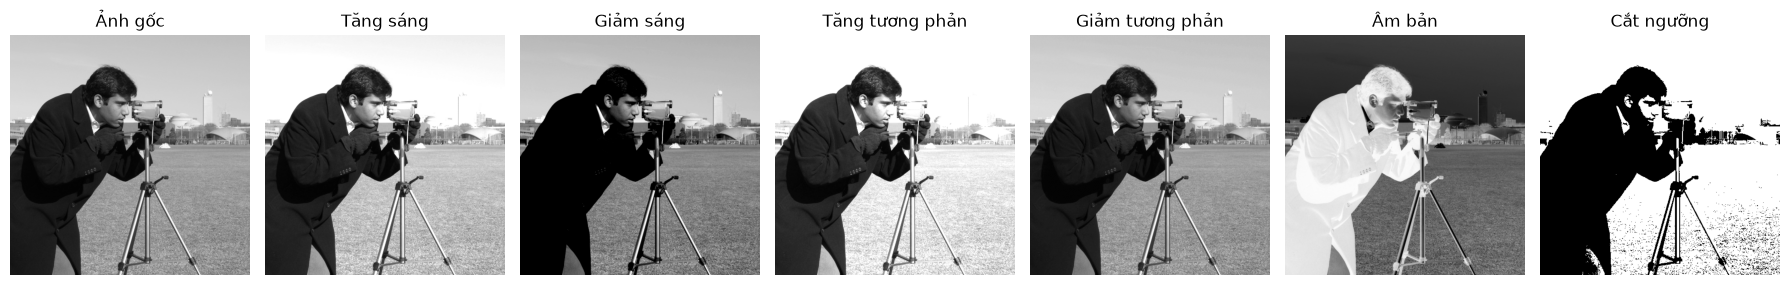

In [2]:
# 1. Thay đổi độ sáng
bright = cv2.add(img, 50)
dark = cv2.subtract(img, 50)

# 2. Thay đổi độ tương phản
high_contrast = cv2.multiply(img, 1.5)
low_contrast = cv2.multiply(img, 0.5)

# 3. Biến đổi âm bản
negative = 255 - img

# 4. Cắt ngưỡng
_, binary = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)

imgs = [img, bright, dark, high_contrast, low_contrast, negative, binary]
titles = ['Ảnh gốc', 'Tăng sáng', 'Giảm sáng', 'Tăng tương phản', 'Giảm tương phản', 'Âm bản', 'Cắt ngưỡng']

fig, axes = plt.subplots(1, 7, figsize=(18, 3))
for ax, im, t in zip(axes, imgs, titles):
    ax.imshow(im, cmap='gray')
    ax.set_title(t)
    ax.axis('off')
plt.tight_layout()
plt.show()

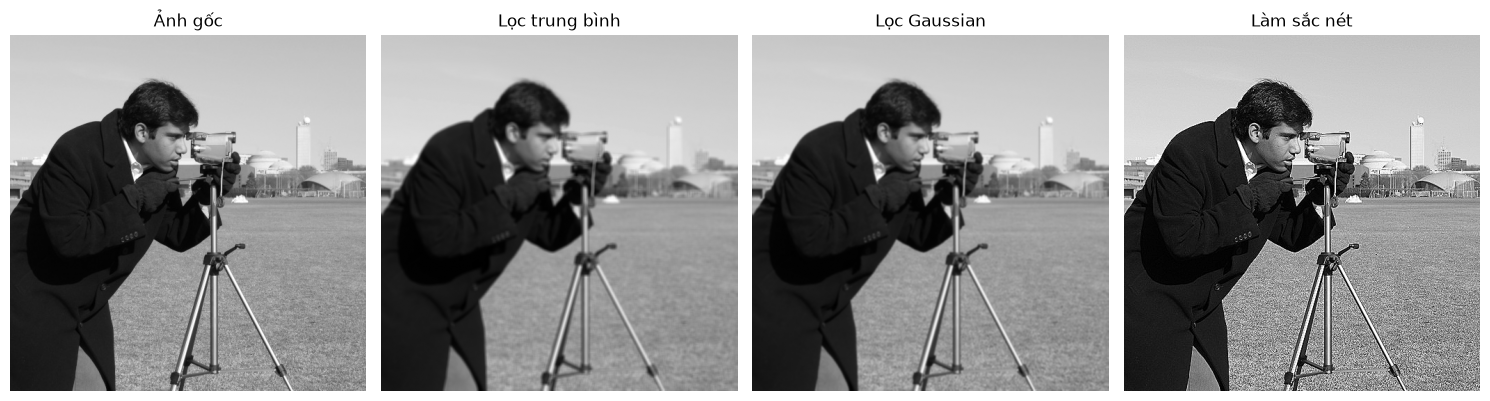

In [3]:
# 1. Lọc trung bình
blur_avg = cv2.blur(img, (5, 5))

# 2. Lọc Gaussian
blur_gauss = cv2.GaussianBlur(img, (5, 5), 0)

# 3. Làm sắc nét
kernel_sharpen = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])
sharpen = cv2.filter2D(img, -1, kernel_sharpen)

imgs = [img, blur_avg, blur_gauss, sharpen]
titles = ['Ảnh gốc', 'Lọc trung bình', 'Lọc Gaussian', 'Làm sắc nét']

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, im, t in zip(axes, imgs, titles):
    ax.imshow(im, cmap='gray')
    ax.set_title(t)
    ax.axis('off')
plt.tight_layout()
plt.show()

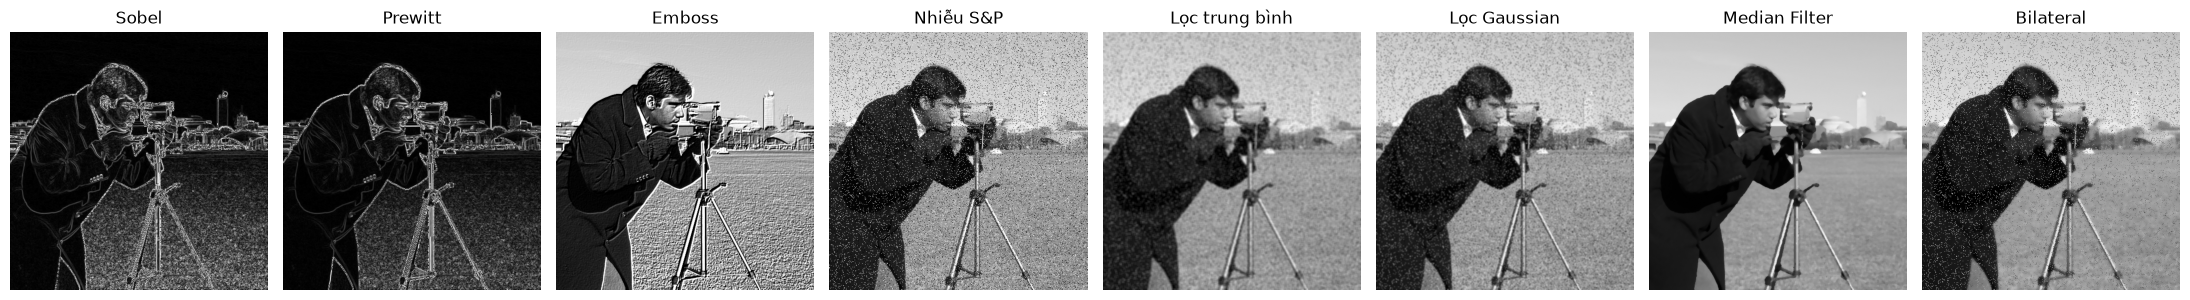

1. Hiệu quả khử nhiễu muối tiêu: Median filter khử nhiễu hoàn hảo nhất; Trung bình và Gaussian chỉ làm nhòe nhiễu.
2. Khả năng bảo toàn biên: Median và Bilateral giữ sắc nét cạnh vượt trội so với các bộ lọc tuyến tính.


In [ ]:
# 1. Phát hiện cạnh Sobel & Prewitt
sobel_x = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)
sobel = cv2.magnitude(sobel_x, sobel_y).astype(np.uint8)

kp_x = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float32)
kp_y = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], dtype=np.float32)
prewitt = cv2.magnitude(cv2.filter2D(img, cv2.CV_64F, kp_x), cv2.filter2D(img, cv2.CV_64F, kp_y)).astype(np.uint8)

# 2. Kernel tùy chỉnh (Emboss)
kernel_emboss = np.array([[-2, -1, 0], [-1, 1, 1], [0, 1, 2]])
emboss = cv2.filter2D(img, -1, kernel_emboss)

# 3. Lọc phi tuyến tính trên ảnh nhiễu muối tiêu
np.random.seed(42)
noisy = img.copy()
n = int(img.size * 0.05)
noisy[np.random.randint(0, img.shape[0], n), np.random.randint(0, img.shape[1], n)] = 255
noisy[np.random.randint(0, img.shape[0], n), np.random.randint(0, img.shape[1], n)] = 0

f_avg = cv2.blur(noisy, (5, 5))
f_gauss = cv2.GaussianBlur(noisy, (5, 5), 0)
f_med = cv2.medianBlur(noisy, 5)
f_bi = cv2.bilateralFilter(noisy, 9, 75, 75)

imgs = [sobel, prewitt, emboss, noisy, f_avg, f_gauss, f_med, f_bi]
titles = ['Sobel', 'Prewitt', 'Emboss', 'Nhiễu S&P', 'Lọc trung bình', 'Lọc Gaussian', 'Median Filter', 'Bilateral']

fig, axes = plt.subplots(1, 8, figsize=(22, 3))
for ax, im, t in zip(axes, imgs, titles):
    ax.imshow(im, cmap='gray')
    ax.set_title(t)
    ax.axis('off')
plt.tight_layout()
plt.show()
